In [1]:
# Architecture 1 - Pure Routing Pattern
# Connect to Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Define all paths
base_path      = '/content/drive/MyDrive/Dissertation'
data_path      = '/content/drive/MyDrive/Dissertation/Data'
results_path   = '/content/drive/MyDrive/Dissertation/Results'
eval_path      = '/content/drive/MyDrive/Dissertation/Evaluation'
arch_path      = '/content/drive/MyDrive/Dissertation/Architectures'

print("✓ All paths defined successfully")

✓ All paths defined successfully


In [3]:
# Load the datasets we need
import pandas as pd

# Load all three workflow datasets
orders    = pd.read_csv(f"{data_path}/olist_orders_dataset.csv")
customers = pd.read_csv(f"{data_path}/olist_customers_dataset.csv")
reviews   = pd.read_csv(f"{data_path}/olist_order_reviews_dataset.csv")
leads     = pd.read_csv(f"{data_path}/olist_marketing_qualified_leads_dataset.csv")
deals     = pd.read_csv(f"{data_path}/olist_closed_deals_dataset.csv")

print("✓ All datasets loaded successfully")
print(f"  Orders:    {len(orders):,} rows")
print(f"  Customers: {len(customers):,} rows")
print(f"  Reviews:   {len(reviews):,} rows")
print(f"  Leads:     {len(leads):,} rows")
print(f"  Deals:     {len(deals):,} rows")

✓ All datasets loaded successfully
  Orders:    99,441 rows
  Customers: 99,441 rows
  Reviews:   99,224 rows
  Leads:     8,000 rows
  Deals:     842 rows


In [4]:
# Create our labelled evaluation queries
# These are the test questions we'll run through all architectures
# Ground truth tells us which workflow each query SHOULD go to

labelled_queries = [

    # W1 - Customer Behaviour Analytics (10 queries)
    {"id": "Q001", "query": "Will this customer come back and buy again?",
     "ground_truth": "W1", "type": "straightforward"},
    {"id": "Q002", "query": "Is this a returning customer or a new one?",
     "ground_truth": "W1", "type": "straightforward"},
    {"id": "Q003", "query": "How likely is this customer to make a repeat purchase?",
     "ground_truth": "W1", "type": "straightforward"},
    {"id": "Q004", "query": "Predict whether this customer will churn.",
     "ground_truth": "W1", "type": "straightforward"},
    {"id": "Q005", "query": "Which customers have not returned in over 6 months?",
     "ground_truth": "W1", "type": "straightforward"},
    {"id": "Q006", "query": "Classify this customer as loyal or at-risk.",
     "ground_truth": "W1", "type": "straightforward"},
    {"id": "Q007", "query": "Are our customers happy?",
     "ground_truth": "W1", "type": "ambiguous"},
    {"id": "Q008", "query": "Why are we losing customers?",
     "ground_truth": "W1", "type": "ambiguous"},
    {"id": "Q009", "query": "Which customers gave us bad reviews and are unlikely to return?",
     "ground_truth": "W1", "type": "multi-intent"},
    {"id": "Q010", "query": "Give me a full overview of our customer journey.",
     "ground_truth": "W1", "type": "multi-intent"},

    # W2 - Marketing Funnel & Campaign Analysis (10 queries)
    {"id": "Q011", "query": "Did this lead convert into a paying customer?",
     "ground_truth": "W2", "type": "straightforward"},
    {"id": "Q012", "query": "Was this marketing lead successfully closed?",
     "ground_truth": "W2", "type": "straightforward"},
    {"id": "Q013", "query": "Predict whether this qualified lead will convert.",
     "ground_truth": "W2", "type": "straightforward"},
    {"id": "Q014", "query": "How effective was our last marketing campaign?",
     "ground_truth": "W2", "type": "straightforward"},
    {"id": "Q015", "query": "Which leads from this month are most likely to close?",
     "ground_truth": "W2", "type": "straightforward"},
    {"id": "Q016", "query": "What is our lead to sale conversion rate this quarter?",
     "ground_truth": "W2", "type": "straightforward"},
    {"id": "Q017", "query": "What is going wrong with our sales this month?",
     "ground_truth": "W2", "type": "ambiguous"},
    {"id": "Q018", "query": "How is our business doing?",
     "ground_truth": "W2", "type": "ambiguous"},
    {"id": "Q019", "query": "Show me leads that converted and also left positive reviews.",
     "ground_truth": "W2", "type": "multi-intent"},
    {"id": "Q020", "query": "Which campaigns brought in customers who later gave 5 star reviews?",
     "ground_truth": "W2", "type": "multi-intent"},

    # W3 - Product & Seller Performance Analysis (10 queries)
    {"id": "Q021", "query": "Is this a positive or negative customer review?",
     "ground_truth": "W3", "type": "straightforward"},
    {"id": "Q022", "query": "Classify this review as positive neutral or negative.",
     "ground_truth": "W3", "type": "straightforward"},
    {"id": "Q023", "query": "What is the sentiment of this product review?",
     "ground_truth": "W3", "type": "straightforward"},
    {"id": "Q024", "query": "Is this seller getting good or bad feedback?",
     "ground_truth": "W3", "type": "straightforward"},
    {"id": "Q025", "query": "Which product categories are getting the most negative reviews?",
     "ground_truth": "W3", "type": "straightforward"},
    {"id": "Q026", "query": "Which sellers have the worst customer satisfaction scores?",
     "ground_truth": "W3", "type": "straightforward"},
    {"id": "Q027", "query": "Why are our ratings dropping?",
     "ground_truth": "W3", "type": "ambiguous"},
    {"id": "Q028", "query": "What can we improve?",
     "ground_truth": "W3", "type": "ambiguous"},
    {"id": "Q029", "query": "Which sellers have the best reviews and highest customer retention?",
     "ground_truth": "W3", "type": "multi-intent"},
    {"id": "Q030", "query": "Which product categories attract the most loyal customers?",
     "ground_truth": "W3", "type": "multi-intent"},
]

# Convert to dataframe
import pandas as pd
queries_df = pd.DataFrame(labelled_queries)

print("✓ Labelled queries created")
print(f"  Total queries: {len(queries_df)}")
print(f"\nBreakdown by workflow:")
print(queries_df['ground_truth'].value_counts().to_string())
print(f"\nBreakdown by type:")
print(queries_df['type'].value_counts().to_string())
print(f"\nFirst 5 queries:")
queries_df.head()

✓ Labelled queries created
  Total queries: 30

Breakdown by workflow:
ground_truth
W1    10
W2    10
W3    10

Breakdown by type:
type
straightforward    18
ambiguous           6
multi-intent        6

First 5 queries:


,id,query,ground_truth,type
0,Q001,Will this customer come back and buy again?,W1,straightforward
1,Q002,Is this a returning customer or a new one?,W1,straightforward
2,Q003,How likely is this customer to make a repeat p...,W1,straightforward
3,Q004,Predict whether this customer will churn.,W1,straightforward
4,Q005,Which customers have not returned in over 6 mo...,W1,straightforward


In [5]:
# Save labelled queries to Evaluation folder
queries_df.to_csv(f"{eval_path}/labelled_queries.csv", index=False)

print("✓ Labelled queries saved to Evaluation folder")
print(f"  Location: {eval_path}/labelled_queries.csv")

✓ Labelled queries saved to Evaluation folder
  Location: /content/drive/MyDrive/Dissertation/Evaluation/labelled_queries.csv


In [6]:
# Cell 6 - Define the Orchestrator Agent
# The orchestrator reads a query and decides which workflow it belongs to
# It uses simple keyword matching - no API key needed at this stage

def orchestrator(query):
    """
    The Orchestrator Agent - Architecture 1 (Pure Routing Pattern)

    Reads a natural language query and routes it to the correct workflow.
    Returns the routing decision and a simple explanation.

    Design Pattern: Routing (Andrew Ng, 2024; Anthropic, 2024)
    """

    query_lower = query.lower()

    # Keywords that suggest each workflow
    w1_keywords = [
        "customer", "return", "loyal", "churn", "repeat",
        "retention", "buyer", "purchase history", "come back",
        "buying again", "lost customer", "at-risk"
    ]

    w2_keywords = [
        "lead", "campaign", "conversion", "marketing", "funnel",
        "channel", "acquisition", "close", "convert", "closed deal",
        "qualified", "organic", "paid", "sales"
    ]

    w3_keywords = [
        "review", "rating", "seller", "product", "sentiment",
        "feedback", "score", "complaint", "satisfaction",
        "star", "positive", "negative", "delivery"
    ]

    # Count keyword matches for each workflow
    w1_score = sum(1 for kw in w1_keywords if kw in query_lower)
    w2_score = sum(1 for kw in w2_keywords if kw in query_lower)
    w3_score = sum(1 for kw in w3_keywords if kw in query_lower)

    scores = {"W1": w1_score, "W2": w2_score, "W3": w3_score}

    # Pick the workflow with the highest score
    best_workflow = max(scores, key=scores.get)
    best_score    = scores[best_workflow]

    # Determine confidence based on score
    if best_score == 0:
        best_workflow = "UNCLEAR"
        confidence    = "LOW"
        explanation   = "No clear workflow keywords found in this query."
    elif best_score >= 3:
        confidence  = "HIGH"
        explanation = f"Routed to {best_workflow} with high confidence " \
                      f"({best_score} keyword matches found)."
    elif best_score >= 2:
        confidence  = "MEDIUM"
        explanation = f"Routed to {best_workflow} with medium confidence " \
                      f"({best_score} keyword matches found)."
    else:
        confidence  = "LOW"
        explanation = f"Routed to {best_workflow} with low confidence " \
                      f"(only {best_score} keyword match found)."

    return {
        "routed_to"  : best_workflow,
        "confidence" : confidence,
        "explanation": explanation,
        "scores"     : scores
    }

print("✓ Orchestrator agent defined successfully")
print("\nLet's test it with one query:")
test = orchestrator("Will this customer come back and buy again?")
print(f"  Query:      'Will this customer come back and buy again?'")
print(f"  Routed to:  {test['routed_to']}")
print(f"  Confidence: {test['confidence']}")
print(f"  Explanation:{test['explanation']}")
print(f"  Scores:     {test['scores']}")

✓ Orchestrator agent defined successfully

Let's test it with one query:
  Query:      'Will this customer come back and buy again?'
  Routed to:  W1
  Confidence: MEDIUM
  Explanation:Routed to W1 with medium confidence (2 keyword matches found).
  Scores:     {'W1': 2, 'W2': 0, 'W3': 0}


In [7]:
# Cell 7 - Define the three Specialist Agents
# Each agent handles only its own workflow

def specialist_w1(query):
    """
    Workflow 1 - Customer Behaviour Analytics Agent
    Task: Predict whether a customer is likely to return
    """
    query_lower = query.lower()

    # Keywords suggesting a customer will return
    positive_signals = [
        "return", "loyal", "repeat", "come back",
        "buying again", "retention", "frequent"
    ]

    # Keywords suggesting a customer will not return
    negative_signals = [
        "churn", "lost", "at-risk", "not returned",
        "inactive", "cancel", "complaint"
    ]

    pos_score = sum(1 for kw in positive_signals if kw in query_lower)
    neg_score = sum(1 for kw in negative_signals if kw in query_lower)

    if neg_score > pos_score:
        classification = "UNLIKELY_TO_RETURN"
        answer = "Based on the signals in this query, " \
                 "the customer shows risk factors for churning."
    elif pos_score > 0:
        classification = "LIKELY_TO_RETURN"
        answer = "Based on the signals in this query, " \
                 "the customer shows positive retention indicators."
    else:
        classification = "NEEDS_MORE_DATA"
        answer = "Not enough information to predict " \
                 "customer return behaviour confidently."

    return {
        "workflow"      : "W1 - Customer Behaviour Analytics",
        "classification": classification,
        "answer"        : answer
    }


def specialist_w2(query):
    """
    Workflow 2 - Marketing Funnel & Campaign Analysis Agent
    Task: Predict whether a lead is likely to convert
    """
    query_lower = query.lower()

    # Keywords suggesting conversion
    positive_signals = [
        "convert", "close", "closed", "won",
        "qualified", "hot", "interested", "signed"
    ]

    # Keywords suggesting no conversion
    negative_signals = [
        "not convert", "lost", "cold", "inactive",
        "dropped", "unqualified", "bounced"
    ]

    pos_score = sum(1 for kw in positive_signals if kw in query_lower)
    neg_score = sum(1 for kw in negative_signals if kw in query_lower)

    if neg_score > pos_score:
        classification = "UNLIKELY_TO_CONVERT"
        answer = "Based on the signals in this query, " \
                 "this lead shows low conversion potential."
    elif pos_score > 0:
        classification = "LIKELY_TO_CONVERT"
        answer = "Based on the signals in this query, " \
                 "this lead shows strong conversion potential."
    else:
        classification = "NEEDS_MORE_DATA"
        answer = "Not enough information to predict " \
                 "lead conversion confidently."

    return {
        "workflow"      : "W2 - Marketing Funnel & Campaign Analysis",
        "classification": classification,
        "answer"        : answer
    }


def specialist_w3(query):
    """
    Workflow 3 - Product & Seller Performance Analysis Agent
    Task: Classify the sentiment of customer reviews
    """
    query_lower = query.lower()

    # Keywords suggesting positive sentiment
    positive_signals = [
        "positive", "good", "great", "excellent",
        "happy", "satisfied", "best", "5 star", "love"
    ]

    # Keywords suggesting negative sentiment
    negative_signals = [
        "negative", "bad", "worst", "terrible",
        "complaint", "unhappy", "dissatisfied",
        "1 star", "2 star", "dropping", "poor"
    ]

    pos_score = sum(1 for kw in positive_signals if kw in query_lower)
    neg_score = sum(1 for kw in negative_signals if kw in query_lower)

    if neg_score > pos_score:
        classification = "NEGATIVE"
        answer = "Based on the signals in this query, " \
                 "the sentiment appears to be negative."
    elif pos_score > neg_score:
        classification = "POSITIVE"
        answer = "Based on the signals in this query, " \
                 "the sentiment appears to be positive."
    else:
        classification = "NEUTRAL"
        answer = "Based on the signals in this query, " \
                 "the sentiment appears to be neutral or mixed."

    return {
        "workflow"      : "W3 - Product & Seller Performance Analysis",
        "classification": classification,
        "answer"        : answer
    }


print("✓ All three specialist agents defined successfully")
print("\nQuick test of each agent:")

r1 = specialist_w1("predict whether this customer will churn")
print(f"\n  W1 Agent: {r1['classification']}")
print(f"  Answer:   {r1['answer']}")

r2 = specialist_w2("did this lead convert into a paying customer")
print(f"\n  W2 Agent: {r2['classification']}")
print(f"  Answer:   {r2['answer']}")

r3 = specialist_w3("this product is getting terrible reviews and complaints")
print(f"\n  W3 Agent: {r3['classification']}")
print(f"  Answer:   {r3['answer']}")

✓ All three specialist agents defined successfully

Quick test of each agent:

  W1 Agent: UNLIKELY_TO_RETURN
  Answer:   Based on the signals in this query, the customer shows risk factors for churning.

  W2 Agent: LIKELY_TO_CONVERT
  Answer:   Based on the signals in this query, this lead shows strong conversion potential.

  W3 Agent: NEGATIVE
  Answer:   Based on the signals in this query, the sentiment appears to be negative.


In [8]:
# Cell 8 - The Complete Architecture 1 Pipeline
# Connects the Orchestrator to the correct Specialist Agent

def run_architecture1(query):
    """
    Complete Architecture 1 - Pure Routing Pattern

    Step 1: Orchestrator reads the query and decides the workflow
    Step 2: Query is routed to the correct specialist agent
    Step 3: Specialist agent returns classification and answer

    Design Pattern: Routing (Andrew Ng, 2024; Anthropic, 2024)
    """

    # Step 1: Orchestrator decides the workflow
    routing_result = orchestrator(query)
    workflow       = routing_result["routed_to"]

    # Step 2: Route to correct specialist agent
    if workflow == "W1":
        specialist_result = specialist_w1(query)
    elif workflow == "W2":
        specialist_result = specialist_w2(query)
    elif workflow == "W3":
        specialist_result = specialist_w3(query)
    else:
        specialist_result = {
            "workflow"      : "UNCLEAR",
            "classification": "OUT_OF_SCOPE",
            "answer"        : "This query does not match any "
                              "of the three business analytics workflows."
        }

    # Step 3: Combine everything into one result
    result = {
        "query"         : query,
        "routed_to"     : workflow,
        "confidence"    : routing_result["confidence"],
        "explanation"   : routing_result["explanation"],
        "classification": specialist_result["classification"],
        "answer"        : specialist_result["answer"]
    }

    return result


# Test with three example queries - one per workflow
print("="*60)
print("ARCHITECTURE 1 - PURE ROUTING PATTERN")
print("Testing with one query per workflow")
print("="*60)

test_queries = [
    "Will this customer come back and buy again?",
    "Did this lead convert into a paying customer?",
    "Is this a positive or negative customer review?"
]

for q in test_queries:
    result = run_architecture1(q)
    print(f"\nQuery:          {result['query']}")
    print(f"Routed to:      {result['routed_to']}")
    print(f"Confidence:     {result['confidence']}")
    print(f"Explanation:    {result['explanation']}")
    print(f"Classification: {result['classification']}")
    print(f"Answer:         {result['answer']}")
    print("-"*60)

ARCHITECTURE 1 - PURE ROUTING PATTERN
Testing with one query per workflow

Query:          Will this customer come back and buy again?
Routed to:      W1
Confidence:     MEDIUM
Explanation:    Routed to W1 with medium confidence (2 keyword matches found).
Classification: LIKELY_TO_RETURN
Answer:         Based on the signals in this query, the customer shows positive retention indicators.
------------------------------------------------------------

Query:          Did this lead convert into a paying customer?
Routed to:      W2
Confidence:     MEDIUM
Explanation:    Routed to W2 with medium confidence (2 keyword matches found).
Classification: LIKELY_TO_CONVERT
Answer:         Based on the signals in this query, this lead shows strong conversion potential.
------------------------------------------------------------

Query:          Is this a positive or negative customer review?
Routed to:      W3
Confidence:     HIGH
Explanation:    Routed to W3 with high confidence (3 keyword matche

In [9]:
# Cell 9 - Evaluate Architecture 1 against all 30 labelled queries
import pandas as pd

# Run every query through Architecture 1
results = []

for _, row in queries_df.iterrows():

    # Run the query through Architecture 1
    result = run_architecture1(row["query"])

    # Check if routing was correct
    is_correct = (result["routed_to"] == row["ground_truth"])

    # Store the full result
    results.append({
        "id"            : row["id"],
        "query"         : row["query"],
        "ground_truth"  : row["ground_truth"],
        "routed_to"     : result["routed_to"],
        "correct"       : is_correct,
        "confidence"    : result["confidence"],
        "explanation"   : result["explanation"],
        "classification": result["classification"],
        "type"          : row["type"]
    })

# Convert to dataframe
results_df = pd.DataFrame(results)

# Overall accuracy
total   = len(results_df)
correct = results_df["correct"].sum()
accuracy = correct / total

print("="*60)
print("ARCHITECTURE 1 EVALUATION RESULTS")
print("="*60)
print(f"\nOverall Routing Accuracy: {accuracy:.1%} ({correct}/{total})")

# Accuracy by query type
print(f"\nAccuracy by Query Type:")
for qtype in ["straightforward", "ambiguous", "multi-intent"]:
    subset   = results_df[results_df["type"] == qtype]
    acc      = subset["correct"].sum() / len(subset)
    print(f"  {qtype:<18}: {acc:.1%} "
          f"({subset['correct'].sum()}/{len(subset)})")

# Accuracy by workflow
print(f"\nAccuracy by Workflow:")
for wf in ["W1", "W2", "W3"]:
    subset = results_df[results_df["ground_truth"] == wf]
    acc    = subset["correct"].sum() / len(subset)
    print(f"  {wf}: {acc:.1%} ({subset['correct'].sum()}/{len(subset)})")

print(f"\nDetailed Results:")
results_df[["id", "query", "ground_truth",
            "routed_to", "correct", "type"]].head(10)

ARCHITECTURE 1 EVALUATION RESULTS

Overall Routing Accuracy: 83.3% (25/30)

Accuracy by Query Type:
  straightforward   : 100.0% (18/18)
  ambiguous         : 66.7% (4/6)
  multi-intent      : 50.0% (3/6)

Accuracy by Workflow:
  W1: 100.0% (10/10)
  W2: 80.0% (8/10)
  W3: 70.0% (7/10)

Detailed Results:


,id,query,ground_truth,routed_to,correct,type
0,Q001,Will this customer come back and buy again?,W1,W1,True,straightforward
1,Q002,Is this a returning customer or a new one?,W1,W1,True,straightforward
2,Q003,How likely is this customer to make a repeat p...,W1,W1,True,straightforward
3,Q004,Predict whether this customer will churn.,W1,W1,True,straightforward
4,Q005,Which customers have not returned in over 6 mo...,W1,W1,True,straightforward
5,Q006,Classify this customer as loyal or at-risk.,W1,W1,True,straightforward
6,Q007,Are our customers happy?,W1,W1,True,ambiguous
7,Q008,Why are we losing customers?,W1,W1,True,ambiguous
8,Q009,Which customers gave us bad reviews and are un...,W1,W1,True,multi-intent
9,Q010,Give me a full overview of our customer journey.,W1,W1,True,multi-intent


In [10]:
# Cell 10 - Analyse the misrouted queries
print("="*60)
print("MISROUTED QUERIES - Architecture 1")
print("="*60)

wrong = results_df[results_df["correct"] == False]

print(f"\nTotal misrouted: {len(wrong)} out of {total}")
print(f"\nDetails of each misrouted query:")
print("-"*60)

for _, row in wrong.iterrows():
    print(f"\nID:           {row['id']}")
    print(f"Query:        {row['query']}")
    print(f"Should go to: {row['ground_truth']}")
    print(f"Went to:      {row['routed_to']}")
    print(f"Query type:   {row['type']}")
    print(f"Explanation:  {row['explanation']}")
    print("-"*60)

MISROUTED QUERIES - Architecture 1

Total misrouted: 5 out of 30

Details of each misrouted query:
------------------------------------------------------------

ID:           Q018
Query:        How is our business doing?
Should go to: W2
Went to:      UNCLEAR
Query type:   ambiguous
Explanation:  No clear workflow keywords found in this query.
------------------------------------------------------------

ID:           Q020
Query:        Which campaigns brought in customers who later gave 5 star reviews?
Should go to: W2
Went to:      W3
Query type:   multi-intent
Explanation:  Routed to W3 with medium confidence (2 keyword matches found).
------------------------------------------------------------

ID:           Q028
Query:        What can we improve?
Should go to: W3
Went to:      UNCLEAR
Query type:   ambiguous
Explanation:  No clear workflow keywords found in this query.
------------------------------------------------------------

ID:           Q029
Query:        Which sellers hav

In [11]:
# Cell 11 - Save Architecture 1 results to Google Drive
import json
from datetime import datetime

# Save detailed results as CSV
results_df.to_csv(
    f"{results_path}/arch1_results.csv",
    index=False
)

# Save summary as JSON
summary = {
    "architecture"        : "Architecture 1 - Pure Routing Pattern",
    "design_pattern"      : "Routing (Andrew Ng, 2024; Anthropic, 2024)",
    "date"                : datetime.now().strftime("%Y-%m-%d"),
    "total_queries"       : int(total),
    "correct"             : int(correct),
    "overall_accuracy"    : round(accuracy, 4),
    "accuracy_by_type"    : {
        "straightforward" : round(results_df[results_df["type"]=="straightforward"]["correct"].mean(), 4),
        "ambiguous"       : round(results_df[results_df["type"]=="ambiguous"]["correct"].mean(), 4),
        "multi-intent"    : round(results_df[results_df["type"]=="multi-intent"]["correct"].mean(), 4)
    },
    "accuracy_by_workflow": {
        "W1"              : round(results_df[results_df["ground_truth"]=="W1"]["correct"].mean(), 4),
        "W2"              : round(results_df[results_df["ground_truth"]=="W2"]["correct"].mean(), 4),
        "W3"              : round(results_df[results_df["ground_truth"]=="W3"]["correct"].mean(), 4)
    },
    "total_misrouted"     : int(len(wrong)),
    "misrouted_ids"       : wrong["id"].tolist()
}

with open(f"{results_path}/arch1_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("✓ Architecture 1 results saved successfully")
print(f"\n  Detailed results: {results_path}/arch1_results.csv")
print(f"  Summary:          {results_path}/arch1_summary.json")
print(f"\nSummary:")
print(f"  Overall Accuracy: {accuracy:.1%}")
print(f"  Misrouted:        {len(wrong)}/30")

✓ Architecture 1 results saved successfully

  Detailed results: /content/drive/MyDrive/Dissertation/Results/arch1_results.csv
  Summary:          /content/drive/MyDrive/Dissertation/Results/arch1_summary.json

Summary:
  Overall Accuracy: 83.3%
  Misrouted:        5/30


/tmp/ipykernel_3026/1573115233.py:128: UserWarning: Glyph 128172 (\N{SPEECH BALLOON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3026/1573115233.py:128: UserWarning: Glyph 129504 (\N{BRAIN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3026/1573115233.py:128: UserWarning: Glyph 128100 (\N{BUST IN SILHOUETTE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3026/1573115233.py:128: UserWarning: Glyph 128226 (\N{PUBLIC ADDRESS LOUDSPEAKER}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3026/1573115233.py:128: UserWarning: Glyph 11088 (\N{WHITE MEDIUM STAR}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3026/1573115233.py:128: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_3026/1573115233.py:132: UserWarning: Glyph 128172 (\N{SPEECH BALLOON}) missing from font(s) DejaVu Sans.
  plt.savefig(diagr

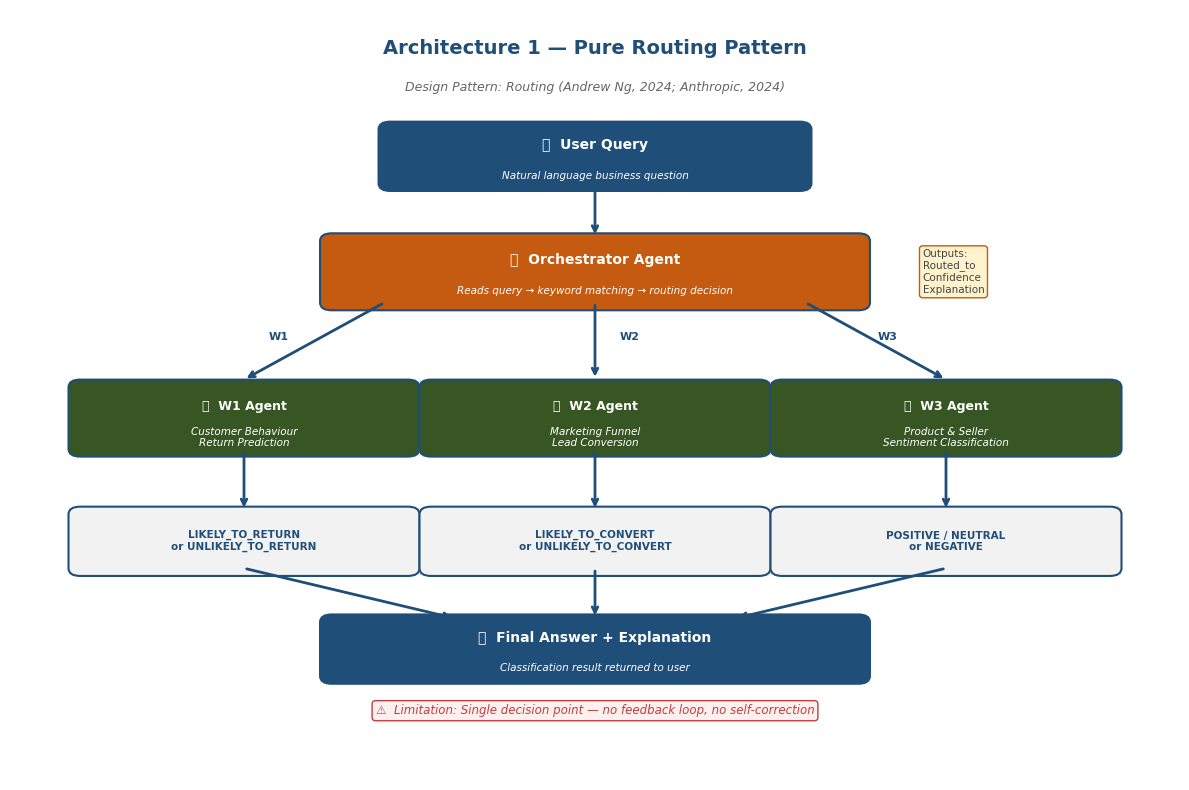


✓ Architecture 1 diagram saved to:
  /content/drive/MyDrive/Dissertation/Results/arch1_diagram.png


In [12]:
# Cell 12 - Architecture 1 Diagram
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch

fig, ax = plt.subplots(1, 1, figsize=(12, 8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 10)
ax.axis('off')

# Title
ax.text(5, 9.5, 'Architecture 1 — Pure Routing Pattern',
        ha='center', va='center', fontsize=14,
        fontweight='bold', color='#1F4E79')
ax.text(5, 9.0, 'Design Pattern: Routing (Andrew Ng, 2024; Anthropic, 2024)',
        ha='center', va='center', fontsize=9, color='#666666', style='italic')

# ── Box helper ──────────────────────────────────────────
def draw_box(ax, x, y, w, h, label, sublabel='',
             facecolor='#2E75B6', textcolor='white', fontsize=10):
    box = mpatches.FancyBboxPatch(
        (x - w/2, y - h/2), w, h,
        boxstyle="round,pad=0.1",
        facecolor=facecolor, edgecolor='#1F4E79', linewidth=1.5
    )
    ax.add_patch(box)
    ax.text(x, y + (0.15 if sublabel else 0), label,
            ha='center', va='center', fontsize=fontsize,
            fontweight='bold', color=textcolor)
    if sublabel:
        ax.text(x, y - 0.25, sublabel,
                ha='center', va='center', fontsize=7.5,
                color=textcolor, style='italic')

# ── Arrow helper ─────────────────────────────────────────
def draw_arrow(ax, x1, y1, x2, y2):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color='#1F4E79',
                                lw=2.0))

# ── USER QUERY ───────────────────────────────────────────
draw_box(ax, 5, 8.1, 3.5, 0.7,
         '💬  User Query',
         'Natural language business question',
         facecolor='#1F4E79', fontsize=10)

draw_arrow(ax, 5, 7.75, 5, 7.05)

# ── ORCHESTRATOR ─────────────────────────────────────────
draw_box(ax, 5, 6.6, 4.5, 0.8,
         '🧠  Orchestrator Agent',
         'Reads query → keyword matching → routing decision',
         facecolor='#C55A11', fontsize=10)

# Confidence label
ax.text(7.8, 6.6, 'Outputs:\nRouted_to\nConfidence\nExplanation',
        ha='left', va='center', fontsize=7.5, color='#444444',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFF3CD',
                  edgecolor='#C55A11', linewidth=1))

# ── ROUTING ARROWS ───────────────────────────────────────
draw_arrow(ax, 3.2, 6.2, 2.0, 5.2)
draw_arrow(ax, 5.0, 6.2, 5.0, 5.2)
draw_arrow(ax, 6.8, 6.2, 8.0, 5.2)

# Route labels
ax.text(2.3, 5.75, 'W1', ha='center', va='center',
        fontsize=8, color='#1F4E79', fontweight='bold')
ax.text(5.3, 5.75, 'W2', ha='center', va='center',
        fontsize=8, color='#1F4E79', fontweight='bold')
ax.text(7.5, 5.75, 'W3', ha='center', va='center',
        fontsize=8, color='#1F4E79', fontweight='bold')

# ── SPECIALIST AGENTS ────────────────────────────────────
draw_box(ax, 2.0, 4.7, 2.8, 0.8,
         '👤  W1 Agent',
         'Customer Behaviour\nReturn Prediction',
         facecolor='#375623', fontsize=9)

draw_box(ax, 5.0, 4.7, 2.8, 0.8,
         '📢  W2 Agent',
         'Marketing Funnel\nLead Conversion',
         facecolor='#375623', fontsize=9)

draw_box(ax, 8.0, 4.7, 2.8, 0.8,
         '⭐  W3 Agent',
         'Product & Seller\nSentiment Classification',
         facecolor='#375623', fontsize=9)

# ── ARROWS DOWN FROM SPECIALISTS ─────────────────────────
draw_arrow(ax, 2.0, 4.3, 2.0, 3.5)
draw_arrow(ax, 5.0, 4.3, 5.0, 3.5)
draw_arrow(ax, 8.0, 4.3, 8.0, 3.5)

# ── OUTPUT BOXES ─────────────────────────────────────────
draw_box(ax, 2.0, 3.1, 2.8, 0.7,
         'LIKELY_TO_RETURN\nor UNLIKELY_TO_RETURN',
         facecolor='#F2F2F2', textcolor='#1F4E79', fontsize=7.5)

draw_box(ax, 5.0, 3.1, 2.8, 0.7,
         'LIKELY_TO_CONVERT\nor UNLIKELY_TO_CONVERT',
         facecolor='#F2F2F2', textcolor='#1F4E79', fontsize=7.5)

draw_box(ax, 8.0, 3.1, 2.8, 0.7,
         'POSITIVE / NEUTRAL\nor NEGATIVE',
         facecolor='#F2F2F2', textcolor='#1F4E79', fontsize=7.5)

# ── ARROWS TO FINAL ANSWER ───────────────────────────────
draw_arrow(ax, 2.0, 2.75, 3.8, 2.1)
draw_arrow(ax, 5.0, 2.75, 5.0, 2.1)
draw_arrow(ax, 8.0, 2.75, 6.2, 2.1)

# ── FINAL ANSWER BOX ─────────────────────────────────────
draw_box(ax, 5.0, 1.7, 4.5, 0.7,
         '✅  Final Answer + Explanation',
         'Classification result returned to user',
         facecolor='#1F4E79', fontsize=10)

# ── LIMITATION NOTE ──────────────────────────────────────
ax.text(5, 0.9,
        '⚠  Limitation: Single decision point — '
        'no feedback loop, no self-correction',
        ha='center', va='center', fontsize=8.5, color='#BF4040',
        style='italic',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#FFF0F0',
                  edgecolor='#BF4040', linewidth=1))

plt.tight_layout()

# Save to Google Drive
diagram_path = f"{results_path}/arch1_diagram.png"
plt.savefig(diagram_path, dpi=150, bbox_inches='tight',
            facecolor='white')
plt.show()

print(f"\n✓ Architecture 1 diagram saved to:")
print(f"  {diagram_path}")